### Fig.S2A

In [3]:
import pandas as pd
K_marbach_cml = pd.read_csv(f"/nas/project1/PAGE_HSim/out/02.prior_perturbseq/exported_kernels/prior_gene_kernels/Marbach.gene_x_gene.csv.gz", index_col=0)
K_msigdb = pd.read_csv(f"/nas/project1/PAGE_HSim/out/02.prior_perturbseq/exported_kernels/prior_gene_kernels/MsigDB.gene_x_gene.csv.gz", index_col=0)
K_depmap = pd.read_csv(f"/nas/project1/PAGE_HSim/out/02.prior_perturbseq/exported_kernels/prior_gene_kernels/DepMap.gene_x_gene.csv.gz", index_col=0)
K_stringdb_medium = pd.read_csv(f"/nas/project1/PAGE_HSim/out/02.prior_perturbseq/exported_kernels/prior_gene_kernels/StringDB.gene_x_gene.csv.gz", index_col=0)
K_periscope = pd.read_csv(f"/nas/project1/PAGE_HSim/out/02.prior_perturbseq/exported_kernels/prior_gene_kernels/Periscope.gene_x_gene.csv.gz", index_col=0)
K_untangled = pd.read_csv(f"/nas/project1/PAGE_HSim/out/02.prior_perturbseq/exported_kernels/prior_gene_kernels/Untangled.gene_x_gene.csv.gz", index_col=0)
K_scgpt = pd.read_csv(f"/nas/project1/PAGE_HSim/out/02.prior_perturbseq/exported_kernels/prior_gene_kernels/scGPT.gene_x_gene.csv.gz", index_col=0)
K_genept = pd.read_csv(f"/nas/project1/PAGE_HSim/out/02.prior_perturbseq/exported_kernels/prior_gene_kernels/genePT.gene_x_gene.csv.gz", index_col=0)
kernels = {
	'Marbach': K_marbach_cml,
    'MsigDB': K_msigdb,
    'DepMap': K_depmap,
    'StringDB': K_stringdb_medium,
    'Periscope': K_periscope,
    'Untangled': K_untangled,
    'scGPT': K_scgpt,
    'genePT': K_genept,
}

del K_marbach_cml, K_msigdb, K_depmap, K_stringdb_medium, K_periscope, K_untangled, K_scgpt, K_genept

print('Kernels are computed!')

Kernels are computed!


In [4]:
import matplotlib.pyplot as plt
strong_corr = []
for prior in kernels.keys():
    for _, i in kernels[prior].iterrows():
        strong_corr.append((i>0.5).sum())

(0.0, 500.0)

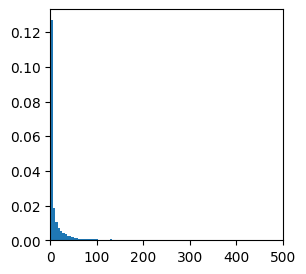

In [5]:
plt.figure(figsize=(3,3))
plt.hist(strong_corr, bins=500, density=True)
plt.xlim(0, 500)
#plt.savefig('Final_Fig.S2A.pdf')

### Fig.S2B

In [1]:
import pandas as pd
gene_level_local_metrics_k100 = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_local_overlap_allpair.csv').set_index('gene')
gene_level_local_metrics_k50 = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_local_overlap_allpair_k50.csv').set_index('gene')

PearsonRResult(statistic=np.float64(0.8948475340085642), pvalue=np.float64(0.0)) SignificanceResult(statistic=np.float64(0.6362947474381855), pvalue=np.float64(0.0))


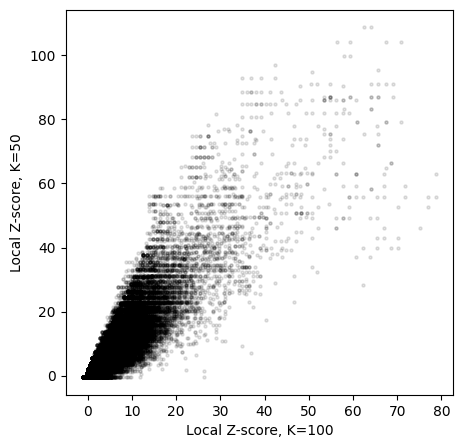

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
plt.figure(figsize=(5,5))
for prior_pair in gene_level_local_metrics_k50.columns.tolist():
    plt.scatter(gene_level_local_metrics_k100[prior_pair], gene_level_local_metrics_k50[prior_pair], s=5, alpha=0.1, label=prior_pair, color='black')

data = pd.DataFrame([gene_level_local_metrics_k50.values.flatten(), gene_level_local_metrics_k100.values.flatten()]).T
data.columns=['x','y']

pearsonr(data['x'], data['y']), spearmanr(data['x'], data['y'])
plt.xlabel('Local Z-score, K=100')
plt.ylabel('Local Z-score, K=50')
print(pearsonr(data['x'], data['y']), spearmanr(data['x'], data['y']))
#plt.savefig('../figure_out/Final_Fig.S2B.png', dpi=600)

### Fig.S2C

PearsonRResult(statistic=np.float64(0.3862916874635331), pvalue=np.float64(0.0)) SignificanceResult(statistic=np.float64(0.33201334982353353), pvalue=np.float64(0.0))


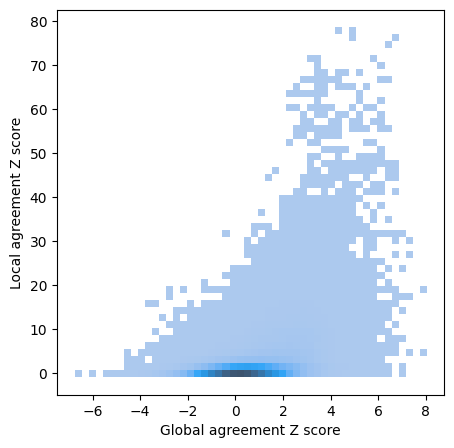

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

gene_level_local_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_local_overlap_allpair.csv')
gene_level_global_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_global_overlap_allpair.csv')
local_metrics = np.sum(gene_level_local_metrics.set_index('gene')>2.5, axis=0)/gene_level_local_metrics.shape[0]
global_metrics = np.sum(gene_level_global_metrics.set_index('gene')>2.5, axis=0)/gene_level_global_metrics.shape[0]
local_metrics = local_metrics.reset_index()
global_metrics = global_metrics.reset_index()

plt.figure(figsize=(5,5))
plot_df = pd.DataFrame([gene_level_global_metrics.set_index('gene').values.flatten(), gene_level_local_metrics.set_index('gene').values.flatten()]).T
plot_df.columns = ['global', 'local']
sns.histplot(plot_df, x='global', y='local', bins=50)
plt.xlabel('Global agreement Z score')
plt.ylabel('Local agreement Z score')
#plt.savefig('./figure_out/Fig.S2C.pdf')
print(pearsonr(plot_df['global'], plot_df['local']), spearmanr(plot_df['global'], plot_df['local']))

### Fig.S2D

In [ ]:
import pandas as pd
import numpy as np

gene_level_local_metrics = {}
gene_level_global_metrics = {}
analysis_targets = ['K562_GWPS','K562_Essential']
for analysis_target in analysis_targets: 
    gene_level_local_metrics[analysis_target] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{analysis_target}_pertspace_gene_local_overlap_allpair.csv').set_index('gene')
    gene_level_global_metrics[analysis_target] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{analysis_target}_pertspace_gene_global_overlap_allpair.csv').set_index('gene')

plot_df_local = []
plot_df_global = []
for analysis_target in analysis_targets:
    local_metrics = np.sum(gene_level_local_metrics[analysis_target]>2.5, axis=0)/gene_level_local_metrics[analysis_target].shape[0]
    global_metrics = np.sum(gene_level_global_metrics[analysis_target]>2.5, axis=0)/gene_level_global_metrics[analysis_target].shape[0]
    plot_df_local.append(local_metrics)
    plot_df_global.append(global_metrics)

plot_df_local = pd.concat(plot_df_local, axis=1)
plot_df_local.columns=analysis_targets
plot_df_global = pd.concat(plot_df_global, axis=1)
plot_df_global.columns=analysis_targets

In [38]:
co_function_agreements = {}
for analysis_target in analysis_targets:
    local_df = gene_level_local_metrics[analysis_target]#.mean(axis=1)
    global_df = gene_level_global_metrics[analysis_target]#.mean(axis=1)
    prior_pert_z_score = (global_df+local_df)/2
    co_function_agreements[analysis_target] = prior_pert_z_score

PearsonRResult(statistic=np.float64(0.7423767112836865), pvalue=np.float64(0.0)) SignificanceResult(statistic=np.float64(0.6103197033692425), pvalue=np.float64(0.0))


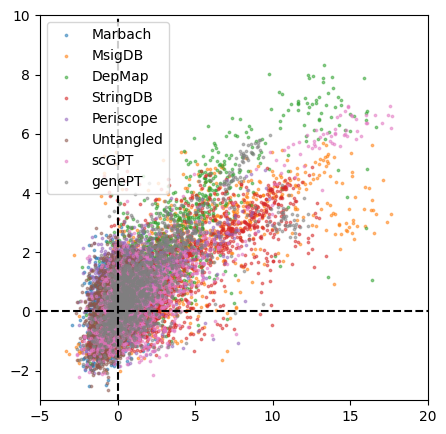

In [ ]:
plt.figure(figsize=(5,5))
x_points = []
y_points = []
for prior in co_function_agreements['K562_GWPS'].columns:
    x = co_function_agreements['K562_GWPS'][prior]
    y = co_function_agreements['K562_Essential'][prior]
    joint_perts = list(set(x.index).intersection(set(y.index)))
    plt.scatter(x.loc[joint_perts], y.loc[joint_perts], s=3, alpha=0.5, label=prior)
    x_points = x_points+x.loc[joint_perts].values.tolist()
    y_points = y_points+y.loc[joint_perts].values.tolist()
plt.legend()
plt.xlim(-5, 20)
plt.ylim(-3, 10)
plt.hlines(y=0, xmin=-5, xmax=20, colors='black', linestyle='dashed')
plt.vlines(x=0, ymin=-5, ymax=20, colors='black', linestyle='dashed')
#plt.hlines(y=2.5, xmin=-5, xmax=20, colors='red', linestyle='dashed')
#plt.vlines(x=2.5, ymin=-5, ymax=20, colors='red', linestyle='dashed')
print(pearsonr(x_points, y_points), spearmanr(x_points, y_points))
#plt.savefig('./figure_out/Fig.S2D.pdf')

### Fig.S2E

/tmp/ipykernel_7161/2371261273.py:18: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(tmp.values, palette=["tab:grey"], alpha=0.5, fill=True, legend=True, bins=50, stat='density', label='All Perturbed Genes')
/tmp/ipykernel_7161/2371261273.py:19: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(tmp[is_essential].values, palette=["black"], alpha=0.5, fill=True, legend=True, bins=50, stat='density', label='Essential Genes')


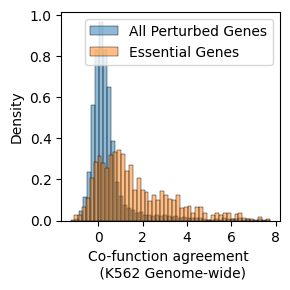

In [ ]:
import gseapy as gp

fig, ax = plt.subplots(nrows=1, figsize=(3,3))#, sharex=True, sharey=True, height_ratios=[1, 1, 1])

common_essential_genes = pd.read_csv("/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/CRISPRInferredCommonEssentials.csv")
# https://depmap.org/portal/data_page/?tab=allData,%20CRISPRInferredCommonEssentials.csv
common_essential_genes = common_essential_genes.map(lambda x: x.split(' ')[0])
common_essential_genes = common_essential_genes.values.flatten().tolist()

tmp = co_function_agreements['K562_GWPS']
is_essential=[]
for g in tmp.index.tolist():
    if g in common_essential_genes:
        is_essential.append(True)
    else:
        is_essential.append(False)

sns.histplot(tmp.values, palette=["tab:grey"], alpha=0.5, fill=True, legend=True, bins=50, stat='density', label='All Perturbed Genes')
sns.histplot(tmp[is_essential].values, palette=["black"], alpha=0.5, fill=True, legend=True, bins=50, stat='density', label='Essential Genes')
plt.xlabel('Co-function agreement \n (K562 Genome-wide)')
plt.legend()
plt.tight_layout()
#plt.savefig('./figure_out/Fig.S2E.pdf')